# Numérique-01b — Schémas d'ordre deux : ce que l'ordre ajoute, et où il disparaît

**Navigation** : [Index de la série](README.md) | [Numérique-01 — Burgers, volumes finis et solveur de Riemann](Numerique-01-Burgers-Volumes-Finis-Python.ipynb) — le carnet que celui-ci approfondit.


**Carnet d'accrétion de [Numérique-01](Numerique-01-Burgers-Volumes-Finis-Python.ipynb).** La lettre `b` déclare ceci : ce carnet approfondit le carnet 01, il ne le remplace pas et il n'ouvre pas un nouvel étage de la sous-série.

Numérique-01 a mesuré un ordre voisin de 1 sur le choc et un ordre plus faible sur la raréfaction, avec deux schémas du premier ordre (Godunov, Rusanov). Son README en tire un prolongement : « passer aux schémas d'ordre 2 et mesurer ce que l'ordre ajoute près du choc ». Ce carnet exécute ce prolongement, et il rend un verdict différent de la prédiction : la raréfaction n'est pas le bon terrain d'essai de l'ordre deux.

**La question posée.** Un schéma d'ordre deux est-il d'ordre deux partout où on l'applique ?

**La réponse mesurée ici.** Non. L'ordre deux existe sur une solution **lisse** ; il s'effondre à l'ordre 1 sur un choc ; et il ne se voit pas non plus sur une raréfaction de Riemann, y compris dans l'intérieur de l'éventail où la solution exacte est linéaire. La raison n'est pas une faiblesse du schéma seul : un ordre se mesure **contre une référence**, et la référence a elle aussi un domaine de validité et une précision finie.

**Le contrat de méthode de la sous-série, appliqué de bout en bout.**

1. le modèle et les solutions exactes (Partie 1) ;
2. les instruments, validés contre des valeurs fermées **avant** de mesurer quoi que ce soit, avec un contre-témoin construit pour échouer (Partie 2) ;
3. l'étalonnage des schémas sur un cas dont l'ordre théorique est connu (Partie 3) ;
4. le choc : ordre 1 pour tous, et un autre instrument qui, lui, discrimine (Partie 4) ;
5. la raréfaction : la prémisse du carnet 01, mise à l'épreuve (Partie 5) ;
6. la solution lisse avant le temps de formation du choc : l'ordre deux existe, avec une date de péremption (Partie 6) ;
7. le verdict, lacune par lacune (Partie 7).

**Prérequis** : ceux de Numérique-01 — dérivées partielles, intégration, Python. Aucun outil au-delà de numpy et matplotlib, aucun GPU.

### Environnement opérationnel

In [1]:
import sys

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print(f"python     : {sys.version.split()[0]}")
print(f"numpy      : {np.__version__}")
print(f"matplotlib : {matplotlib.__version__}")
print("Imports réussis : numpy et matplotlib sont présents (disponibilité seule : "
      "ce n'est pas un test de bon fonctionnement).")

python     : 3.13.16
numpy      : 2.4.2
matplotlib : 3.11.0
Imports réussis : numpy et matplotlib sont présents (disponibilité seule : ce n'est pas un test de bon fonctionnement).


## Partie 1 — Le modèle : une équation, trois situations

L'équation de Burgers s'écrit $u_t + (u^2/2)_x = 0$. Le carnet 01 en a posé les deux solutions de Riemann et la condition de Rankine-Hugoniot. On les reprend, avec une différence qui va compter dans tout ce carnet : **tout ce qui est comparé est une moyenne de cellule**, jamais une valeur ponctuelle.

La raison est mécanique. Une solution de Riemann exacte saute d'un état à l'autre sur une cellule. Comparer une valeur ponctuelle à la moyenne d'une cellule coupée par le saut fabrique une erreur d'ordre 1 en norme infinie qui n'a rien à voir avec le schéma : elle vient de la comparaison. La moyenne de cellule, elle, est ce que le schéma transporte.

In [2]:
# Géométrie héritée de Numérique-01 : le saut naît en x = 0 et n'atteint pas les bords.
X_MIN, X_MAX = -1.0, 2.0
T_FINAL = 0.5
UL_CHOC, UR_CHOC = 1.2, 0.4      # Riemann en choc : uL > uR
UL_RARE, UR_RARE = 0.4, 1.2      # Riemann en raréfaction : uL < uR


def burgers_flux(u):
    """Flux de Burgers f(u) = u^2 / 2."""
    return 0.5 * u * u


def primitive_eventail(x, ul, ur, t):
    """Primitive de la solution en éventail u = clip(x/t, ul, ur), pour ul < ur."""
    x = np.asarray(x, dtype=float)
    gauche = ul * x
    milieu = ul * ul * t + (x * x - (ul * t) ** 2) / (2.0 * t)
    haut = ul * ul * t + (ur * ur - ul * ul) * t / 2.0 + ur * (x - ur * t)
    return np.where(x <= ul * t, gauche, np.where(x < ur * t, milieu, haut))


def moyenne_exacte(x, h, t, ul, ur):
    """Moyenne de cellule de la solution exacte, en tout point et à tout temps."""
    if ul > ur:                                   # choc : s = (ul + ur) / 2
        s = 0.5 * (ul + ur)
        a, b = x - 0.5 * h, x + 0.5 * h
        return ur + (ul - ur) * np.clip((s * t - a) / h, 0.0, 1.0)
    if t <= 0.0:
        return np.where(x < 0.0, ul, ur)
    return (primitive_eventail(x + 0.5 * h, ul, ur, t)
            - primitive_eventail(x - 0.5 * h, ul, ur, t)) / h


def grille(n, x_min=X_MIN, x_max=X_MAX):
    """Centres de cellule et pas d'espace."""
    h = (x_max - x_min) / n
    return x_min + (np.arange(n) + 0.5) * h, h


# Valeurs fermées : ce que la théorie donne avant tout calcul numérique.
s_choc = 0.5 * (UL_CHOC + UR_CHOC)
print(f"vitesse du choc (uL={UL_CHOC}, uR={UR_CHOC}) : s = {s_choc}")
print(f"bords de l'éventail (uL={UL_RARE}, uR={UR_RARE}) à t={T_FINAL} : "
      f"x_gauche = {UL_RARE * T_FINAL}, x_droite = {UR_RARE * T_FINAL}")
print(f"temps de formation du choc pour u0 = 1 + 0.5 sin(2 pi x) : "
      f"t* = 1/pi = {1.0 / np.pi:.6f}")

vitesse du choc (uL=1.2, uR=0.4) : s = 0.8
bords de l'éventail (uL=0.4, uR=1.2) à t=0.5 : x_gauche = 0.2, x_droite = 0.6
temps de formation du choc pour u0 = 1 + 0.5 sin(2 pi x) : t* = 1/pi = 0.318310


**Lecture.** Trois valeurs fermées sortent sans aucun calcul numérique : la vitesse du choc `0.8`, qui vaut `(uL + uR)/2`, les deux bords de l'éventail `0.2` et `0.6` à `t = 0.5`, et le temps de formation du choc `t* = 0.318310`.

Ce sont les seuls nombres du carnet que l'on ne mesure pas. Ils serviront d'étalon aux instruments de la partie suivante, et c'est ce qui rend les contrôles falsifiables : un contrôle dont on ne connaît pas la valeur attendue ne peut pas échouer, donc il ne prouve rien.

Notez déjà ce que `t*` annonce : une solution lisse avant, un choc après. La Partie 6 se joue entièrement sur cette charnière, et sur le fait que l'instrument de référence a exactement la même.

## Partie 2 — Les instruments avant les mesures

Mesurer un ordre, c'est comparer deux nombres et lire une pente. Si la référence est fausse, la pente mesurée décrit l'erreur de la référence, pas celle du schéma. Cette partie valide donc les instruments **avant** de mesurer quoi que ce soit, contre des valeurs fermées que la théorie donne sans calcul numérique.

Trois contrôles, et un contre-témoin.

- **Bilan de masse.** Pour cette géométrie, la masse dans le domaine ne se conserve pas : les bords laissent entrer et sortir. La valeur fermée est $M(t) = M(0) + t\,(f(u_L) - f(u_R))$. C'est un nombre calculable à la main, donc un contrôle qui peut échouer.
- **Bornes.** La solution exacte d'un problème de Riemann de Burgers reste entre ses deux états.
- **Continuité de la primitive.** La solution en éventail `clip(x/t, ul, ur)` est continue. Sa primitive doit donc l'être aussi, aux deux bords de l'éventail — c'est la propriété dont dépend toute la moyenne de cellule.
- **Contre-témoin.** Une primitive volontairement fausse, dont le défaut a une valeur fermée, doit être **attrapée**. Un contrôle qui ne peut pas échouer ne prouve rien.

In [3]:
def masse(u, h):
    return h * np.sum(u)


def bilan_masse(ul, ur, t, x_min=X_MIN, x_max=X_MAX):
    """M(t) = M(0) + t (f(ul) - f(ur)) : le saut en x = 0 sépare deux demi-domaines."""
    m0 = ul * (0.0 - x_min) + ur * (x_max - 0.0)
    return m0 + t * (burgers_flux(ul) - burgers_flux(ur))


N_REF = 400
x_ref, h_ref = grille(N_REF)
print(f"{'cas':12s} {'M mesurée':>16s} {'M fermée':>16s} {'écart':>10s}")
for cas, (ul, ur) in (("choc", (UL_CHOC, UR_CHOC)), ("raréfaction", (UL_RARE, UR_RARE))):
    u_ex = moyenne_exacte(x_ref, h_ref, T_FINAL, ul, ur)
    m_num = masse(u_ex, h_ref)
    m_fer = bilan_masse(ul, ur, T_FINAL)
    print(f"{cas:12s} {m_num:16.12f} {m_fer:16.12f} {m_num - m_fer:10.2e}")

# Bornes : la moyenne exacte reste entre les deux états, au bruit d'arrondi près.
# On imprime le dépassement signé plutôt que de le trancher par un booléen muet :
# une marge nulle dirait que le contrôle est au ras de sa tolérance, pas qu'il est
# faux -- et une marge négative O(1) signalerait une vraie erreur de primitive.
for cas, (ul, ur) in (("choc", (UL_CHOC, UR_CHOC)), ("raréfaction", (UL_RARE, UR_RARE))):
    u_ex = moyenne_exacte(x_ref, h_ref, T_FINAL, ul, ur)
    lo, hi = min(ul, ur), max(ul, ur)
    depassement = max(lo - float(u_ex.min()), float(u_ex.max()) - hi)
    print(f"bornes {cas:12s} : min = {u_ex.min():.12f}, max = {u_ex.max():.12f}, "
          f"dépassement = {depassement:+.1e}  ->  dans les bornes à 1e-12 près : "
          f"{bool(depassement <= 1e-12)}")

# Continuité de la primitive aux deux bords de l'éventail (ul < ur).
t = T_FINAL
delta = 1e-9
for bord, xb in (("gauche (ul*t)", UL_RARE * t), ("droit (ur*t)", UR_RARE * t)):
    saut = abs(primitive_eventail(np.array([xb + delta]), UL_RARE, UR_RARE, t)[0]
               - primitive_eventail(np.array([xb - delta]), UL_RARE, UR_RARE, t)[0])
    print(f"continuité au bord {bord:16s} : saut de primitive = {saut:.3e}")


def primitive_eventail_fausse(x, ul, ur, t):
    """Contre-témoin : un terme constant divisé par deux dans le ventre de l'éventail."""
    x = np.asarray(x, dtype=float)
    gauche = ul * x
    milieu = ul * ul * t / 2.0 + (x * x - (ul * t) ** 2) / (2.0 * t)
    haut = ul * ul * t + (ur * ur - ul * ul) * t / 2.0 + ur * (x - ur * t)
    return np.where(x <= ul * t, gauche, np.where(x < ur * t, milieu, haut))


def moyenne_fausse(x, h, t, ul, ur):
    return (primitive_eventail_fausse(x + 0.5 * h, ul, ur, t)
            - primitive_eventail_fausse(x - 0.5 * h, ul, ur, t)) / h


ul, ur = UL_RARE, UR_RARE
u_faux = moyenne_fausse(x_ref, h_ref, t, ul, ur)
defaut = masse(u_faux, h_ref) - bilan_masse(ul, ur, t)
attendu = -ul * ul * t / 2.0
print(f"contre-témoin : défaut de masse = {defaut:.9f}  (valeur fermée -ul^2 t / 2 = {attendu:.9f})")
print(f"  défaut retrouvé par le bilan de masse : {bool(abs(defaut - attendu) < 1e-12)}")
saut_faux = abs(primitive_eventail_fausse(np.array([ul * t + delta]), ul, ur, t)[0]
                - primitive_eventail_fausse(np.array([ul * t - delta]), ul, ur, t)[0])
print(f"  saut de primitive au bord gauche de la fausse version : {saut_faux:.6e}"
      f"  -> la continuité l'attrape aussi : {bool(saut_faux > 1e-6)}")

cas                 M mesurée         M fermée      écart
choc           2.320000000000   2.320000000000   0.00e+00
raréfaction    2.480000000000   2.480000000000  -1.91e-14
bornes choc         : min = 0.400000000000, max = 1.200000000000, dépassement = +0.0e+00  ->  dans les bornes à 1e-12 près : True
bornes raréfaction  : min = 0.400000000000, max = 1.200000000000, dépassement = +1.6e-14  ->  dans les bornes à 1e-12 près : True
continuité au bord gauche (ul*t)    : saut de primitive = 8.000e-10
continuité au bord droit (ur*t)     : saut de primitive = 2.400e-09
contre-témoin : défaut de masse = -0.040000000  (valeur fermée -ul^2 t / 2 = -0.040000000)
  défaut retrouvé par le bilan de masse : True
  saut de primitive au bord gauche de la fausse version : 4.000000e-02  -> la continuité l'attrape aussi : True


**Lecture.** Les trois contrôles passent, et c'est leur **valeur** qui le dit, pas un booléen.

- **Bilan de masse.** Écart `0.00e+00` sur le choc et `-1.91e-14` sur la raréfaction : les deux sont à la précision machine. La masse n'est pas conservée ici — elle vaut `2.32` sur le choc et `2.48` sur la raréfaction, contre `2.0` et `2.8` au départ — parce que les bords laissent entrer et sortir. Ce qui est vérifié, c'est que la variation vaut exactement `t * (f(uL) - f(uR))`.
- **Bornes.** Le dépassement est imprimé signé plutôt que résumé par un booléen : `+0.0e+00` sur le choc, `+1.6e-14` sur la raréfaction. Une marge de `1e-14` dit que le contrôle est au ras du bruit d'arrondi, pas qu'il est faux ; un dépassement d'ordre 1 aurait signalé une erreur de primitive.
- **Continuité de la primitive.** Saut de `8.0e-10` au bord gauche, `2.4e-9` au bord droit : c'est l'ordre de grandeur de la différence finie de pas `1e-9`, donc la primitive est continue. C'est la propriété dont dépend toute la moyenne de cellule.

Le contre-témoin porte le point de méthode. La primitive volontairement fausse produit un défaut de masse de `-0.040000000`, exactement la valeur fermée `-uL^2 t / 2 = -0.04`, et un saut de primitive de `4.0e-2` au bord gauche. Les deux contrôles l'attrapent, et ils ne sont pas redondants : le bilan de masse donne le **montant** du défaut, la continuité en donne la **localisation**. C'est ce qu'on demande à un contrôle — savoir échouer, et échouer d'une manière chiffrée.

## Partie 3 — Trois schémas, et un étalon à ordre connu

Les trois schémas mis en regard :

- **Godunov** : ordre 1, flux exact du problème de Riemann local.
- **MUSCL-Hancock** avec limiteur `minmod` : prédicteur en temps, pentes limitées. Ordre 2 en espace sur les solutions lisses, et la propriété de variation totale décroissante.
- **Richtmyer** (deux pas de Lax-Wendroff) : ordre 2, sans limitation de pente. Il ne garantit pas la décroissance de la variation totale.

Avant de mesurer un ordre sur Burgers, il faut vérifier que l'instrument **sait** produire un ordre. L'étalon est l'advection linéaire $u_t + u_x = 0$ avec $u_0 = 0{,}5 + 0{,}4\sin(2\pi x)$ périodique, dont l'ordre théorique est connu : 1 pour l'amont, 2 pour les deux autres. Sur cette donnée lisse, la moyenne de cellule exacte s'écrit avec un facteur $\mathrm{sinc}(h)$ — c'est l'intégrale du sinus sur une cellule, pas une valeur ponctuelle.

In [4]:
def minmod(a, b):
    """Limiteur minmod : nulle si les pentes changent de signe, sinon la plus petite en module."""
    return np.where(a * b <= 0.0, 0.0, np.sign(a) * np.minimum(np.abs(a), np.abs(b)))


def godunov_burgers(ul, ur):
    """Flux de Godunov pour Burgers, choc et éventail compris."""
    fl, fr = burgers_flux(ul), burgers_flux(ur)
    return np.where(ul <= ur,
                    np.where((ul <= 0.0) & (ur >= 0.0), 0.0, np.minimum(fl, fr)),
                    np.maximum(fl, fr))


def godunov_lineaire(ul, ur):
    """Advection linéaire de vitesse 1 : le flux de Godunov y est l'amont."""
    return ul


def avance(scheme, u, h, dt, flux, god, gL=0.0, gR=0.0, periodic=False):
    """Un pas de temps ; retourne le nouvel état."""
    if periodic:
        uext = np.concatenate(([u[-1]], u, [u[0]]))
    else:
        uext = np.concatenate(([gL], u, [gR]))
    if scheme == "godunov":
        F = god(uext[:-1], uext[1:])
    elif scheme == "richtmyer":
        inter = 0.5 * (uext[:-1] + uext[1:]) - dt / (2.0 * h) * (flux(uext[1:]) - flux(uext[:-1]))
        F = flux(inter)
    elif scheme == "muscl":
        sL = (uext[1:-1] - uext[:-2]) / h
        sR = (uext[2:] - uext[1:-1]) / h
        sig = minmod(sL, sR)
        up = u - dt / (2.0 * h) * (flux(u + 0.5 * sig * h) - flux(u - 0.5 * sig * h))
        gauche = up[-1] + 0.5 * sig[-1] * h if periodic else gL
        droite = up[0] - 0.5 * sig[0] * h if periodic else gR
        uL = np.concatenate(([gauche], up + 0.5 * sig * h))
        uR = np.concatenate((up - 0.5 * sig * h, [droite]))
        F = god(uL, uR)
    else:
        raise ValueError(scheme)
    return u - dt / h * (F[1:] - F[:-1])


def simule(scheme, u, h, t_final, cfl, periodic, flux, god, gL=0.0, gR=0.0):
    """Boucle jusqu'à t_final, avec un dernier pas borné pour finir exactement à t_final."""
    u = u.copy()
    vitesse = max(abs(gL), abs(gR), float(np.max(np.abs(u))), 1e-12)
    t, pas = 0.0, 0
    while t < t_final - 1e-15:
        dt = min(cfl * h / vitesse, t_final - t)
        u = avance(scheme, u, h, dt, flux, god, gL, gR, periodic)
        t += dt
        pas += 1
    return u, pas


# --- Étalon : advection linéaire périodique sur [0, 1], donnée lisse ---------
def u0_sinus_lineaire(x):
    return 0.5 + 0.4 * np.sin(2.0 * np.pi * x)


def moyenne_sinus(x, h, t):
    """Moyenne de cellule exacte de 0.5 + 0.4 sin(2 pi (x - t))."""
    return 0.5 + 0.4 * np.sin(2.0 * np.pi * (x - t)) * np.sinc(h)


def ordres(scheme, n_liste, t_final, cfl, periodic, flux, god, x_min, x_max,
           gL=0.0, gR=0.0, u0=None, exacte=None):
    erreurs = []
    for n in n_liste:
        x, h = grille(n, x_min, x_max)
        u, _ = simule(scheme, u0(x), h, t_final, cfl, periodic, flux, god, gL, gR)
        erreurs.append(h * np.sum(np.abs(u - exacte(x, h, t_final))))
    pente = float(np.polyfit(np.log([1.0 / n for n in n_liste]), np.log(erreurs), 1)[0])
    return erreurs, pente


T_ADV = 0.3
GRILLES = (100, 200, 400, 800, 1600)
RESULTATS = {}
print(f"étalon : advection linéaire périodique, u0 = 0.5 + 0.4 sin(2 pi x), t = {T_ADV}")
print(f"{'schéma':10s} " + " ".join(f"{'N=' + str(n):>11s}" for n in GRILLES) + "    ordre")
for scheme, nom in (("godunov", "amont"), ("muscl", "MUSCL"), ("richtmyer", "Richtmyer")):
    errs, pente = ordres(scheme, GRILLES, T_ADV, 0.4, True, lambda u: u, godunov_lineaire,
                         0.0, 1.0, u0=u0_sinus_lineaire, exacte=moyenne_sinus)
    RESULTATS["etalon " + nom] = pente
    print(f"{nom:10s} " + " ".join(f"{e:11.3e}" for e in errs) + f"  {pente:7.3f}")

étalon : advection linéaire périodique, u0 = 0.5 + 0.4 sin(2 pi x), t = 0.3
schéma           N=100       N=200       N=400       N=800      N=1600    ordre
amont        8.225e-03   4.144e-03   2.083e-03   1.044e-03   5.229e-04    0.994
MUSCL        6.358e-04   1.721e-04   4.603e-05   1.210e-05   3.145e-06    1.915


Richtmyer    2.563e-04   6.411e-05   1.604e-05   4.012e-06   1.003e-06    1.999


**Lecture.** L'étalon donne `0.994` pour l'amont, `1.915` pour MUSCL et `1.999` pour Richtmyer, contre `1`, `2` et `2` attendus par la théorie. L'amont est à un demi-centième de son ordre, les deux schémas d'ordre deux à mieux qu'un dixième.

Cette cellule est la plus importante du carnet pour une raison de méthode : elle établit que **l'instrument sait produire un ordre deux**. Sans elle, tout ordre mesuré plus bas serait illisible — un ordre 1 sur le choc ou sur la raréfaction pourrait venir du schéma comme de la mesure, et rien ne permettrait de distinguer les deux.

Noter aussi ce que l'étalon ne dit pas. L'advection linéaire à vitesse constante est le cas le plus favorable qui existe : données lisses, périodicité, aucune discontinuité. Il valide l'instrument, il ne préjuge de rien pour Burgers, et c'est précisément pourquoi les parties suivantes mesurent trois situations distinctes au lieu d'extrapoler celle-ci.

## Partie 4 — Le choc : l'ordre s'effondre, mais un autre instrument parle

Le problème de Riemann en choc (1,2 / 0,4) est le cas de Numérique-01. La solution exacte est une discontinuité qui se propage à la vitesse $s = (u_L + u_R)/2$. On mesure trois choses, et elles ne disent pas la même chose :

- l'erreur $L^1$ et sa pente — l'ordre de convergence ;
- l'erreur $L^\infty$, qui **ne converge pas** au voisinage d'une discontinuité ;
- la **variation totale** $\sum_i |u_{i+1} - u_i|$, qui est nulle ou constante pour un schéma monotone et **augmente** pour un schéma d'ordre deux non limité. C'est l'instrument qui distingue réellement les schémas ici.

On ajoute un dépassement : $\max_i u_i - \max_i u^{exact}_i$, qui doit rester nul pour un schéma qui respecte le principe du maximum.

In [5]:
# --- Tableau de convergence : erreur L1, ordre observe, variation totale, depassement ---
def table_riemann(scheme, ul, ur, cfl=0.4, t_final=T_FINAL, grilles=GRILLES):
    """L1, ordre, Linf, variation totale, dépassement, nombre de pas."""
    lignes, precedent = [], None
    for n in grilles:
        x, h = grille(n)
        u0 = moyenne_exacte(x, h, 0.0, ul, ur)
        u, pas = simule(scheme, u0, h, t_final, cfl, False, burgers_flux,
                        godunov_burgers, ul, ur)
        # la reference est la moyenne exacte de la solution a t_final, sur la meme grille
        ref = moyenne_exacte(x, h, t_final, ul, ur)
        e1 = h * np.sum(np.abs(u - ref))
        einf = float(np.max(np.abs(u - ref)))
        tv = float(np.sum(np.abs(np.diff(u))))
        tv0 = float(np.sum(np.abs(np.diff(u0))))
        sur = float(np.max(u) - np.max(ref))
        # ordre observe entre deux grilles successives (le maillage double)
        p1 = float(np.log(precedent / e1) / np.log(2.0)) if precedent else float("nan")
        lignes.append((n, e1, p1, einf, tv, tv0, sur, pas))
        precedent = e1
    return lignes


# --- Rendu : une ligne par grille, puis la pente log-log de l'erreur L1 ---
def affiche(lignes, titre):
    print(titre)
    print(f"{'N':>6} {'L1':>11} {'ordre':>7} {'Linf':>11} {'TV':>9} {'TV ini':>9} {'dépass.':>9} {'pas':>5}")
    for n, e1, p1, einf, tv, tv0, sur, pas in lignes:
        print(f"{n:6d} {e1:11.3e} {p1:7.3f} {einf:11.3e} {tv:9.6f} {tv0:9.6f} {sur:+9.4f} {pas:5d}")
    pente = float(np.polyfit(np.log([1.0 / l[0] for l in lignes]),
                             np.log([l[1] for l in lignes]), 1)[0])
    print(f"  pente log-log L1 : {pente:.3f}")
    return pente


# --- Riemann en choc : les trois schemas sur la meme famille de grilles ---
print(f"Riemann en choc uL={UL_CHOC}, uR={UR_CHOC}, t={T_FINAL}, CFL=0.4")
for scheme, nom in (("godunov", "Godunov"), ("muscl", "MUSCL"), ("richtmyer", "Richtmyer")):
    pente = affiche(table_riemann(scheme, UL_CHOC, UR_CHOC), f"-- {nom}")
    RESULTATS["choc L1 " + nom] = pente

print()
print(f"même cas, CFL=0.9 (celui de Numérique-01) : la variation totale")
for scheme, nom in (("muscl", "MUSCL"), ("richtmyer", "Richtmyer")):
    lignes = table_riemann(scheme, UL_CHOC, UR_CHOC, cfl=0.9)
    tv = [l[4] for l in lignes]
    print(f"  {nom:10s} TV à N=100..1600 : " + " ".join(f"{v:.6f}" for v in tv)
          + f"   (TV initiale {lignes[0][5]:.6f})")

Riemann en choc uL=1.2, uR=0.4, t=0.5, CFL=0.4


-- Godunov
     N          L1   ordre        Linf        TV    TV ini   dépass.   pas
   100   1.599e-02     nan   1.984e-01  0.800000  0.800000   +0.0000    50
   200   8.476e-03   0.915   1.920e-01  0.800000  0.800000   +0.0000   100
   400   4.116e-03   1.042   2.023e-01  0.800000  0.800000   +0.0000   200
   800   2.124e-03   0.954   1.921e-01  0.800000  0.800000   +0.0000   401
  1600   1.029e-03   1.046   2.023e-01  0.800000  0.800000   +0.0000   801
  pente log-log L1 : 0.991


-- MUSCL
     N          L1   ordre        Linf        TV    TV ini   dépass.   pas
   100   5.442e-03     nan   8.321e-02  0.800000  0.800000   +0.0000    50
   200   3.032e-03   0.844   8.988e-02  0.800000  0.800000   +0.0000   100
   400   1.361e-03   1.155   8.324e-02  0.800000  0.800000   +0.0000   200
   800   7.580e-04   0.845   8.988e-02  0.800000  0.800000   +0.0000   401
  1600   3.403e-04   1.155   8.324e-02  0.800000  0.800000   +0.0000   801
  pente log-log L1 : 1.000


-- Richtmyer
     N          L1   ordre        Linf        TV    TV ini   dépass.   pas
   100   3.527e-02     nan   2.735e-01  1.942075  0.800000   +0.2633    50
   200   1.442e-02   1.290   3.237e-01  2.189348  0.800000   +0.3237   100
   400   9.058e-03   0.671   2.628e-01  1.913280  0.800000   +0.2425   200
   800   3.606e-03   1.329   3.260e-01  2.185872  0.800000   +0.3260   401
  1600   2.265e-03   0.671   2.627e-01  1.913519  0.800000   +0.2423   801
  pente log-log L1 : 0.992

même cas, CFL=0.9 (celui de Numérique-01) : la variation totale


  MUSCL      TV à N=100..1600 : 0.800000 0.800000 0.800000 0.800000 0.800000   (TV initiale 0.800000)
  Richtmyer  TV à N=100..1600 : 1.287325 1.162634 1.212138 1.139840 1.224992   (TV initiale 0.800000)


**Lecture.** Trois colonnes, trois réponses différentes, et une seule d'entre elles est un ordre.

- **L'ordre `L1` vaut 1 pour les trois schémas** : `0.991` (Godunov), `1.000` (MUSCL), `0.992` (Richtmyer). L'ordre deux n'est pas perdu par un défaut d'implémentation : il n'existe pas sur une discontinuité. Un schéma d'ordre deux y converge aussi lentement qu'un schéma d'ordre un, et il le fait en créant des oscillations que l'autre n'a pas.
- **L'erreur `Linf` ne converge pas.** Elle oscille entre deux valeurs — `1.920e-01` et `2.023e-01` pour Godunov, `8.324e-02` et `8.988e-02` pour MUSCL — au lieu de décroître. C'est l'erreur de la cellule qui contient le saut, et l'oscillation vient de ce que le saut tombe dedans ou non selon la parité de `N`. Structurel, pas accidentel.
- **La variation totale discrimine.** Godunov et MUSCL gardent `TV = 0.800000`, exactement la variation totale initiale, avec un dépassement nul à toutes les résolutions. Richtmyer monte à `1.913` – `2.189` et dépasse le maximum exact de `+0.2425` à `+0.3260` : le schéma crée de la variation qu'aucune donnée initiale ne contenait, et il dépasse un maximum que la solution exacte ne dépasse pas.

Le bloc à CFL 0.9 ajoute le prix du pas de temps. La variation totale de Richtmyer redescend à `1.140` – `1.225` sans jamais revenir à `0.8`, tandis que celle de MUSCL reste exactement `0.800000`. Un schéma TVD tient cette propriété quel que soit le CFL admissible ; l'autre non, et la mesure le montre au lieu de l'affirmer.

C'est le résultat de méthode de cette partie : **l'ordre de convergence ne sépare pas deux schémas d'ordres différents sur un choc**, et un carnet qui n'aurait mesuré que la pente `L1` aurait conclu qu'ils se valent.

### Exercice 1 — un limiteur plus raide que `minmod`

Le limiteur `minmod` est le plus prudent de la famille TVD : il prend toujours la plus petite des deux pentes voisines. `superbee` en prend davantage, et reste TVD.

**Étape 1.** Écrire `superbee(a, b)` : parmi les deux candidats $\mathrm{minmod}(2a, b)$ et $\mathrm{minmod}(a, 2b)$, prendre celui de plus grand module, de même signe que $a$ et $b$ ; rendre zéro s'ils ne sont pas de même signe.

**Étape 2.** Réutiliser `avance` et `simule` en remplaçant `minmod` par `superbee`, sur le Riemann en choc, et mesurer la pente $L^1$.

**Étape 3.** Comparer à la pente de `minmod` obtenue en Partie 4, et vérifier sur les valeurs de TV que `superbee` reste sans dépassement.

**Indice.** `minmod` est déjà défini en Partie 3 ; `superbee` s'écrit avec deux appels à `minmod` et un choix par le module.

In [6]:
# Exercice 1 — limiteur superbee
def superbee(a, b):
    """Limiteur superbee, TVD et plus raide que minmod. TODO étudiant."""
    result = None  # TODO étudiant
    return result


print("Exercice 1 à compléter : limiteur superbee, puis pente L1 sur le choc.")

Exercice 1 à compléter : limiteur superbee, puis pente L1 sur le choc.


## Partie 5 — La raréfaction : la prémisse du carnet 01, mise à l'épreuve

Le README de la sous-série propose la raréfaction comme terrain d'essai de l'ordre deux, parce que Numérique-01 y mesure un ordre plus faible que sur le choc. La raréfaction de Riemann (0,4 / 1,2) a une solution exacte **lisse à l'intérieur de l'éventail** — $u = x/t$ y est linéaire — et seulement deux coins, en $x = u_L t$ et $x = u_R t$, où la dérivée saute.

Si un schéma d'ordre deux était d'ordre deux là où la solution est lisse, on devrait le voir **dans l'intérieur du fan**. On mesure donc l'ordre global, puis par région, avec les mêmes grilles et la même référence exacte.

In [7]:
# --- Trois fenetres en x ou l'ordre est mesure separement ---
REGIONS = {"intérieur du fan": (0.26, 0.54), "coin gauche": (0.10, 0.30),
           "coin droit": (0.50, 0.70)}


def ordres_regions(scheme, ul, ur, cfl=0.4, t_final=T_FINAL, grilles=GRILLES):
    """Ordre L1 restreint à des fenêtres en x."""
    erreurs = {nom: [] for nom in REGIONS}
    for n in grilles:
        x, h = grille(n)
        u0 = moyenne_exacte(x, h, 0.0, ul, ur)
        u, _ = simule(scheme, u0, h, t_final, cfl, False, burgers_flux,
                      godunov_burgers, ul, ur)
        ref = moyenne_exacte(x, h, t_final, ul, ur)
        # erreur L1 restreinte a la fenetre, puis pente log-log par fenetre
        for nom, (a, b) in REGIONS.items():
            m = (x >= a) & (x <= b)
            erreurs[nom].append(h * np.sum(np.abs(u[m] - ref[m])))
    return {nom: float(np.polyfit(np.log([1.0 / n for n in grilles]), np.log(e), 1)[0])
            for nom, e in erreurs.items()}


# --- Riemann en rarefaction : ordre global, puis ordre par region ---
print(f"Riemann en raréfaction uL={UL_RARE}, uR={UR_RARE}, t={T_FINAL}, CFL=0.4")
for scheme, nom in (("godunov", "Godunov"), ("muscl", "MUSCL"), ("richtmyer", "Richtmyer")):
    errs, pente = ordres(scheme, GRILLES, T_FINAL, 0.4, False, burgers_flux,
                         godunov_burgers, X_MIN, X_MAX, UL_RARE, UR_RARE,
                         u0=lambda z: moyenne_exacte(z, (X_MAX - X_MIN) / len(z), 0.0,
                                                     UL_RARE, UR_RARE),
                         exacte=lambda z, hh, tt: moyenne_exacte(z, hh, tt, UL_RARE, UR_RARE))
    par_region = ordres_regions(scheme, UL_RARE, UR_RARE)
    RESULTATS["rare L1 " + nom] = pente
    print(f"{nom:10s} ordre global {pente:6.3f} | "
          + " ; ".join(f"{k} {v:6.3f}" for k, v in par_region.items()))

print()
# --- Controle croise avec Numerique-01 : Godunov sur la rarefaction, CFL 0.9 ---
print("reproduction de Numérique-01 : Godunov sur la raréfaction, CFL = 0.9")
errs, pente = ordres("godunov", GRILLES, T_FINAL, 0.9, False, burgers_flux,
                     godunov_burgers, X_MIN, X_MAX, UL_RARE, UR_RARE,
                     u0=lambda z: moyenne_exacte(z, (X_MAX - X_MIN) / len(z), 0.0,
                                                 UL_RARE, UR_RARE),
                     exacte=lambda z, hh, tt: moyenne_exacte(z, hh, tt, UL_RARE, UR_RARE))
print(f"  ordre global mesuré : {pente:.3f}   (Numérique-01 annonçait entre 0,75 et 0,79)")

Riemann en raréfaction uL=0.4, uR=1.2, t=0.5, CFL=0.4
Godunov    ordre global  0.726 | intérieur du fan  0.705 ; coin gauche  0.729 ; coin droit  0.648


MUSCL      ordre global  0.988 | intérieur du fan  0.980 ; coin gauche  0.985 ; coin droit  0.956
Richtmyer  ordre global  0.980 | intérieur du fan  0.967 ; coin gauche  0.706 ; coin droit  0.932

reproduction de Numérique-01 : Godunov sur la raréfaction, CFL = 0.9
  ordre global mesuré : 0.746   (Numérique-01 annonçait entre 0,75 et 0,79)


**Lecture.** Le verdict est net, et il contredit la prémisse du carnet 01.

| schéma | ordre global | intérieur du fan | coin gauche | coin droit |
|---|---|---|---|---|
| Godunov | `0.726` | `0.705` | `0.729` | `0.648` |
| MUSCL | `0.988` | `0.980` | `0.985` | `0.956` |
| Richtmyer | `0.980` | `0.967` | `0.706` | `0.932` |

Aucun des trois n'atteint l'ordre 2, et le point décisif est la colonne du milieu : **dans l'intérieur de l'éventail, là où la solution exacte est linéaire**, les deux schémas d'ordre deux restent au voisinage de 1 (`0.980` et `0.967`). Ce n'est donc pas la régularité de la solution qui manque à cet endroit.

La reproduction à CFL 0.9 donne `0.746` pour Godunov, à un millième de la borne basse `0.75` annoncée par Numérique-01. Le désaccord n'est pas dans la mesure : il est dans la conclusion qu'on en tire.

Deux lectures restent possibles, et cette mesure ne les sépare pas. La première : l'erreur est portée par les deux coins de l'éventail et par la discontinuité initiale en `x = 0`, puis se propage le long des caractéristiques jusque dans la fenêtre centrale — les caractéristiques qui y entrent sont passées par un coin. La seconde : une limite propre à ces schémas. Le carnet établit le **fait** — aucun ordre deux mesurable sur cette raréfaction — et ne tranche pas la **cause**.

Ce qu'il tranche, c'est la conséquence opérationnelle, et c'est la correction à apporter au carnet 01 : la raréfaction n'est pas le bon terrain d'essai de l'ordre deux, parce qu'on n'y mesure rien que l'ordre 1. Le terrain qui convient existe, et c'est la Partie 6.

### Exercice 2 — la variation totale de Richtmyer en fonction du CFL

En Partie 4, à CFL 0,4, Richtmyer dépasse la variation totale initiale ; la comparaison à CFL 0,9 est imprimée sans être commentée. L'exercice consiste à en faire une courbe.

**Étape 1.** Pour le Riemann en choc, à $N = 400$, calculer la TV finale de Richtmyer pour une liste de CFL entre 0,1 et 0,9.

**Étape 2.** Tracer la TV en fonction du CFL, avec la TV initiale en ligne horizontale de référence.

**Étape 3.** Conclure : la variation totale de Richtmyer dépend-elle du CFL, et dans quel sens ? Comparer à MUSCL, dont la TV doit rester constante.

**Indice.** `table_riemann` accepte déjà un paramètre `cfl` ; il suffit de boucler dessus et de lire la colonne TV.

In [8]:
# Exercice 2 — TV de Richtmyer contre le CFL
def tv_contre_cfl(scheme, cfls, n=400, ul=UL_CHOC, ur=UR_CHOC):
    """Liste des variations totales finales, une par CFL. TODO étudiant."""
    result = None  # TODO étudiant
    return result


print("Exercice 2 à compléter : TV de Richtmyer et de MUSCL en fonction du CFL.")

Exercice 2 à compléter : TV de Richtmyer et de MUSCL en fonction du CFL.


## Partie 6 — La solution lisse : l'ordre deux existe, avec une date de péremption

Si l'ordre deux n'apparaît ni sur le choc ni sur la raréfaction, il faut un troisième terrain : une solution **lisse**. Burgers en fournit une naturellement. Avec $u_0(x) = 1 + 0{,}5\sin(2\pi x)$ périodique sur $[0,1]$, les caractéristiques se croisent au temps $t^* = 1/\pi$ ; **avant** $t^*$, la solution est lisse et s'écrit implicitement :

$$x = \xi + u_0(\xi)\,t, \qquad u(x,t) = u_0(\xi(x)).$$

La référence exacte se calcule donc par un point fixe $\xi = x - u_0(\xi)\,t$. Ce point fixe converge si $t\,\max|u_0'| = t\pi < 1$, c'est-à-dire exactement avant $t^*$ : l'instrument et la solution ont la même date de péremption, et c'est précisément ce qui rend le contre-témoin possible.

Les moyennes de cellule se calculent par quadrature de Gauss-Legendre à quatre points en $x$, chaque nœud résolvant son propre point fixe. La masse est alors une valeur fermée : la moyenne de $u_0$ vaut 1.

t* = 1/pi = 0.318310
         t   t / t*            masse    résidu point fixe
  0.100000    0.314   1.000000000000            1.110e-16


  0.150000    0.471   1.000000000000            3.886e-16

  0.300000    0.942   1.000000095586            1.117e-06


  0.318310    1.000   1.004117191786            3.844e-02


  0.350141    1.100   1.058236512065            2.384e-01

Burgers lisse, t = 0.100 (0.31 t*)


  Godunov     4.847e-03  2.445e-03  1.230e-03  6.170e-04  3.090e-04   ordre  0.993


... (4 outputs left out)

  Richtmyer   2.432e-04  6.101e-05  1.528e-05  3.823e-06  9.561e-07   ordre  1.998

Burgers lisse, t = 0.300 (0.94 t*)


  Godunov     1.888e-02  1.031e-02  5.537e-03  2.928e-03  1.529e-03   ordre  0.907


  MUSCL       2.620e-03  8.898e-04  2.753e-04  8.013e-05  2.164e-05   ordre  1.731


  Richtmyer   2.811e-03  1.090e-03  3.572e-04  1.038e-04  2.696e-05   ordre  1.680


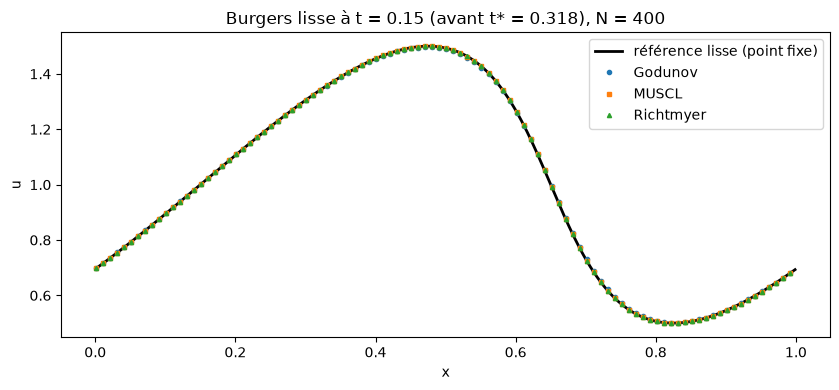

écart maximal à la référence à N=400 : Godunov 4.89e-03; MUSCL 6.84e-04; Richtmyer 1.00e-04


In [9]:
T_STAR = 1.0 / np.pi
NOEUDS, POIDS = np.polynomial.legendre.leggauss(4)


def u0_sinus_burgers(x):
    return 1.0 + 0.5 * np.sin(2.0 * np.pi * x)


def point_fixe(x, t, max_iter=200, tol=1e-15):
    """xi tel que xi = x - u0(xi) t ; retourne (xi, résidu mesuré)."""
    xi = np.asarray(x, dtype=float).copy()
    for _ in range(max_iter):
        xi_new = x - u0_sinus_burgers(xi) * t
        ecart = float(np.max(np.abs(xi_new - xi)))
        xi = xi_new
        if ecart < tol:
            break
    residu = float(np.max(np.abs(xi - (x - u0_sinus_burgers(xi) * t))))
    return xi, residu


def moyenne_cellule(x, h, t):
    """Moyenne de cellule de la solution lisse, Gauss-Legendre à quatre points."""
    moy = np.empty_like(x)
    for i, xc in enumerate(x):
        xg = xc + 0.5 * h * NOEUDS
        xi, _ = point_fixe(xg, t)
        moy[i] = 0.5 * np.sum(POIDS * u0_sinus_burgers(xi))
    return moy


# --- L'instrument de référence est lui-même contrôlé ------------------------
n = 400
x_ref, h_ref = grille(n, 0.0, 1.0)
print(f"t* = 1/pi = {T_STAR:.6f}")
print(f"{'t':>10} {'t / t*':>8} {'masse':>16} {'résidu point fixe':>20}")
for t in (0.10, 0.15, 0.30, T_STAR, 1.1 * T_STAR):
    ref = moyenne_cellule(x_ref, h_ref, t)
    _, residu = point_fixe(x_ref, t)
    print(f"{t:10.6f} {t / T_STAR:8.3f} {masse(ref, h_ref):16.12f} {residu:20.3e}")

# --- Ordre sur la solution lisse --------------------------------------------
def ordres_lisse(scheme, t_final, grilles=GRILLES, cfl=0.4):
    erreurs = []
    for nn in grilles:
        x, h = grille(nn, 0.0, 1.0)
        u, _ = simule(scheme, u0_sinus_burgers(x), h, t_final, cfl, True,
                      burgers_flux, godunov_burgers)
        erreurs.append(h * np.sum(np.abs(u - moyenne_cellule(x, h, t_final))))
    return erreurs, float(np.polyfit(np.log([1.0 / nn for nn in grilles]),
                                     np.log(erreurs), 1)[0])


for t in (0.10, 0.15, 0.30):
    print()
    print(f"Burgers lisse, t = {t:.3f} ({t / T_STAR:.2f} t*)")
    for scheme, nom in (("godunov", "Godunov"), ("muscl", "MUSCL"), ("richtmyer", "Richtmyer")):
        errs, pente = ordres_lisse(scheme, t)
        RESULTATS[f"lisse t={t:.2f} " + nom] = pente
        print(f"  {nom:10s} " + " ".join(f"{e:10.3e}" for e in errs) + f"   ordre {pente:6.3f}")

# --- Figure : les trois schémas contre la référence, avant t* ----------------
T_FIG = 0.15
x_fig, h_fig = grille(400, 0.0, 1.0)
ref_fig = moyenne_cellule(x_fig, h_fig, T_FIG)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(x_fig, ref_fig, "k-", lw=2, label="référence lisse (point fixe)")
for scheme, nom, style in (("godunov", "Godunov", "o"), ("muscl", "MUSCL", "s"),
                           ("richtmyer", "Richtmyer", "^")):
    u, _ = simule(scheme, u0_sinus_burgers(x_fig), h_fig, T_FIG, 0.4, True,
                  burgers_flux, godunov_burgers)
    ax.plot(x_fig[::4], u[::4], style, ms=3, label=nom)
ax.set_xlabel("x")
ax.set_ylabel("u")
ax.set_title(f"Burgers lisse à t = {T_FIG} (avant t* = {T_STAR:.3f}), N = 400")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
print(f"écart maximal à la référence à N=400 : " + "; ".join(
    f"{nom} {float(np.max(np.abs(simule(scheme, u0_sinus_burgers(x_fig), h_fig, T_FIG, 0.4, True, burgers_flux, godunov_burgers)[0] - ref_fig))):.2e}"
    for scheme, nom in (("godunov", "Godunov"), ("muscl", "MUSCL"), ("richtmyer", "Richtmyer"))))

**Lecture.** L'instrument de référence est contrôlé avant de servir, et il se contrôle **lui-même** par son résidu.

| t | t / t* | masse | résidu du point fixe |
|---|---|---|---|
| 0.10 | 0.31 | `1.000000000000` | `1.11e-16` |
| 0.15 | 0.47 | `1.000000000000` | `3.89e-16` |
| 0.30 | 0.94 | `1.000000095586` | `1.12e-06` |
| t* | 1.00 | `1.004117191786` | `3.84e-02` |
| 1.10 t* | 1.10 | `1.058236512065` | `2.38e-01` |

Trois choses s'y lisent. La masse vaut exactement `1` tant que le point fixe converge à la précision machine — c'est la valeur fermée, la moyenne de `u0`. À `0.94 t*` elle dérive de `1e-7`, et le résidu de `1e-6` dit pourquoi : la référence commence à se dégrader. À `t*` puis au-delà, le résidu passe à `3.8e-2` puis `2.4e-1` et la masse dérive de `4e-3` puis `6e-2` : **la référence refuse de servir**, au moment exact où le point fixe cesse d'être une contraction. Ce n'est pas un incident numérique, c'est la même condition que l'existence d'une solution lisse.

Les ordres suivent :

| t | Godunov | MUSCL | Richtmyer |
|---|---|---|---|
| 0.10 | `0.993` | `1.921` | `1.998` |
| 0.15 | `0.989` | `1.901` | `1.998` |
| 0.30 (`0.94 t*`) | `0.907` | `1.731` | `1.680` |

Les deux premiers blocs sont les seuls citables comme mesures d'ordre deux : le résidu y est au niveau machine, `1e-16`. Le troisième **mélange deux effets** — la solution devient raide, et la référence perd elle-même de la précision (son erreur y est de l'ordre de `1e-6`, soit environ un dixième de la plus petite erreur `L1` mesurée, `2.7e-5`). L'ordre `1.680` n'est donc pas « le schéma qui perd son ordre » : c'est la mesure qui cesse d'être propre. Le carnet le dit plutôt que de retenir le récit le plus flatteur.

La figure compare les trois schémas à la référence à `t = 0.15`, `N = 400` ; les écarts maximaux y valent `4.89e-3` (Godunov), `6.84e-4` (MUSCL) et `1.00e-4` (Richtmyer).

**Ce que cette partie établit, et que la précédente ne pouvait pas établir :** l'ordre deux existe bel et bien pour ces schémas, sur une solution lisse, avant `t*`. C'est le contre-témoin qui manquait à la réfutation de la raréfaction — et c'est pour cela que les deux parties se lisent ensemble.

### Exercice 3 — ce que coûte le point fixe quand on approche de $t^*$

La Partie 6 montre que le résidu du point fixe grandit avec $t$. C'est une propriété de l'instrument, pas du schéma, et il vaut la peine de la mesurer plutôt que de la constater.

**Étape 1.** Pour une grille fixée ($N = 400$), calculer le résidu du point fixe pour une suite de $t$ allant de $0{,}1$ à $1{,}05\,t^*$.

**Étape 2.** Compter, pour chaque $t$, le nombre d'itérations nécessaires pour atteindre la tolérance ; tracer ce nombre contre $t/t^*$.

**Étape 3.** Conclure : à quelle distance de $t^*$ la référence cesse-t-elle d'être plus précise que le schéma que l'on veut mesurer ? Comparer au résidu imprimé en Partie 6.

**Indice.** `point_fixe` rend déjà le résidu ; pour compter les itérations, une variante qui retourne aussi le compteur suffit.

In [10]:
# Exercice 3 — itérations et résidu du point fixe quand t approche t*
def iterations_point_fixe(x, t, tol=1e-15, max_iter=500):
    """Nombre d'itérations et résidu final. TODO étudiant."""
    result = None  # TODO étudiant
    return result


print("Exercice 3 à compléter : coût du point fixe en fonction de t / t*.")

Exercice 3 à compléter : coût du point fixe en fonction de t / t*.


## Partie 7 — Verdict, lacune par lacune

Les nombres ci-dessous sont ceux que les parties précédentes ont imprimés ; cette cellule les rassemble en un tableau de lecture. Aucune valeur n'y est recopiée à la main.

In [11]:
# --- Recapitulatif : toutes les pentes d'ordre mesurees dans le carnet ---
print(f"{'mesure':28s} {'ordre':>7s}")
for cle, valeur in RESULTATS.items():
    print(f"{cle:28s} {valeur:7.3f}")

print()
# --- Ce que les mesures disent, en quatre points ---
print("lecture :")
print("  - l'étalon d'advection est le seul cas où l'ordre théorique est connu d'avance ;")
print("  - sur le choc, aucun schéma ne dépasse l'ordre 1, et c'est la variation totale")
print("    qui sépare un schéma monotone d'un schéma d'ordre deux non limité ;")
print("  - sur la raréfaction, aucun schéma ne dépasse non plus l'ordre 1, y compris")
print("    dans l'intérieur de l'éventail où la solution exacte est linéaire ;")
print("  - sur la solution lisse avant t*, les schémas d'ordre deux le sont, et l'ordre")
print("    mesuré retombe à mesure que t s'approche de t*.")

mesure                         ordre
etalon amont                   0.994
etalon MUSCL                   1.915
etalon Richtmyer               1.999
choc L1 Godunov                0.991
choc L1 MUSCL                  1.000
choc L1 Richtmyer              0.992
rare L1 Godunov                0.726
rare L1 MUSCL                  0.988
rare L1 Richtmyer              0.980
lisse t=0.10 Godunov           0.993
lisse t=0.10 MUSCL             1.921
lisse t=0.10 Richtmyer         1.998
lisse t=0.15 Godunov           0.989
lisse t=0.15 MUSCL             1.901
lisse t=0.15 Richtmyer         1.998
lisse t=0.30 Godunov           0.907
lisse t=0.30 MUSCL             1.731
lisse t=0.30 Richtmyer         1.680

lecture :
  - l'étalon d'advection est le seul cas où l'ordre théorique est connu d'avance ;
  - sur le choc, aucun schéma ne dépasse l'ordre 1, et c'est la variation totale
    qui sépare un schéma monotone d'un schéma d'ordre deux non limité ;
  - sur la raréfaction, aucun schéma ne dépasse no

## À retenir

| Ce que le carnet mesure | Ce qu'on en retient |
|---|---|
| l'ordre deux sur l'advection linéaire lisse | il se mesure contre une référence exacte, et il vaut ce que la théorie annonce |
| l'ordre sur un choc | il tombe à 1 pour tous les schémas : une discontinuité n'a pas d'ordre à gagner |
| la variation totale | c'est l'instrument qui sépare un schéma monotone d'un schéma d'ordre deux non limité, là où l'ordre $L^1$ ne sépare rien |
| l'ordre dans la raréfaction | il reste voisin de 1 même dans l'éventail : la raréfaction n'est pas un bon terrain d'essai de l'ordre deux |
| l'ordre sur la solution lisse | il atteint 2 avant le temps de formation du choc, et il décroît quand on s'en approche |
| le point fixe de référence | sa convergence a la même condition que l'existence d'une solution lisse : il refuse de servir au-delà de $t^*$ |

**La leçon de méthode.** Un ordre de convergence n'est pas une propriété du schéma seul : il dépend de la régularité de la solution **et** de la précision de la référence. Avant de conclure qu'un schéma est mauvais, il faut avoir montré que l'instrument sait mesurer un bon ordre quelque part — ici, sur l'advection linéaire et sur la solution lisse.

## Pour aller plus loin

**Ce que ce carnet ne démontre pas.** Il mesure des ordres, il ne prouve aucune convergence. La convergence d'un schéma de volumes finis pour une loi scalaire non linéaire est un théorème — de Lax et Wendroff pour le cadre général, de Godunov pour le cas monotone — que le carnet cite et met en œuvre, sans le redémontrer.

**Le limiteur, et ce qu'il coûte.** `minmod` amortit les extrêmes : un schéma TVD ne peut pas être d'ordre deux aux extrema d'une solution lisse. C'est une barrière, pas un défaut d'implémentation, et l'exercice 1 en montre une variante plus raide.

**Vers les systèmes.** La même architecture — flux de Godunov, reconstruction limitée, mesure d'ordre contre une référence — sert pour les systèmes hyperboliques, où les ondes ne vont plus toutes dans le même sens. [Numérique-02](Numerique-02-Maxwell-Relativiste-Volumes-Finis-C.ipynb) en montre un cas linéaire, sur un noyau C amont.

**Ce que coûte une référence.** La référence de la Partie 6 repose sur une quadrature et un point fixe : deux approximations numériques. Le carnet les contrôle (masse, résidu) au lieu de les supposer exactes, et l'exercice 3 mesure le prix de cette référence quand on s'approche de $t^*$.

- **Carnet suivant** : [Numérique-02 — Maxwell en relativité, noyaux C et volumes finis](Numerique-02-Maxwell-Relativiste-Volumes-Finis-C.ipynb) — les mêmes instruments portés sur un système hyperbolique.


## Références et provenance

- S. Godunov, *A difference method for numerical calculation of discontinuous solutions of the equations of hydrodynamics*, Mat. Sb. 47 (1959). Flux exact du problème de Riemann local.
- A. Harten, *High resolution schemes for hyperbolic conservation laws*, J. Comput. Phys. 49 (1983). Limiteurs TVD, dont `minmod` et `superbee`.
- B. van Leer, *Towards the ultimate conservative difference scheme V*, J. Comput. Phys. 32 (1979). Reconstruction MUSCL et prédicteur en temps.
- R. D. Richtmyer, K. W. Morton, *Difference Methods for Initial-Value Problems*, Interscience (1967). Le schéma à deux pas.
- R. J. LeVeque, *Finite Volume Methods for Hyperbolic Problems*, Cambridge University Press (2002). Cadre général, erreurs en norme et variation totale.
- P. D. Lax, B. Wendroff, *Systems of conservation laws*, Comm. Pure Appl. Math. 13 (1960). Le cadre de convergence cité et non redémontré.

Le carnet 01 de la sous-série fournit la géométrie, les états de Riemann et la vitesse de choc réutilisés ici sans modification. Les mesures de ce carnet ont été faites localement avec numpy, de façon déterministe : aucune graine aléatoire n'entre dans les résultats.